# 05 · From model to money
**Question:** what is this worth, and what should the bank do on Monday morning?

⚠️ The dataset has no cost or revenue fields. The values below are **explicit scenario assumptions** (cost per call, value per subscriber) set in `src/config.py` and stress-tested, not facts.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import data, modelling, business, segmentation
from src.config import *
pd.set_option('display.width', 200); pd.set_option('display.float_format', '{:.3f}'.format)
df = data.clean(data.load_raw())

In [2]:
k = json.load(open(PROCESSED/'kpis.json')); imp = k['impact']
print(f"Break-even conversion rate at ${COST_PER_CALL:.0f}/call and ${VALUE_PER_SUBSCRIBER:.0f}/subscriber: {imp['break_even_conversion_rate']:.1%}")
pd.DataFrame(imp['capacity_constrained']).T.rename(columns={'model_capture':'subscribers captured (model)','random_capture':'subscribers captured (random)','conversion_rate':'conversion in contacted group'})

Break-even conversion rate at $5/call and $150/subscriber: 3.3%


,subscribers captured (model),subscribers captured (random),conversion in contacted group
20pct,0.667,0.202,0.372
30pct,0.739,0.303,0.275
50pct,0.829,0.495,0.189


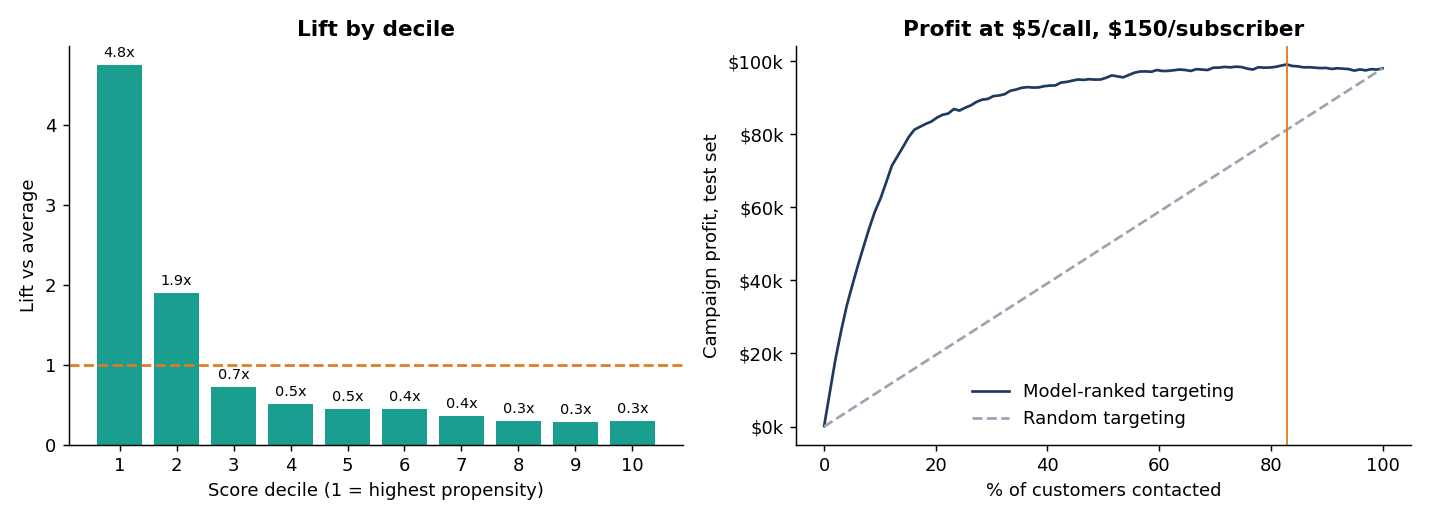

In [3]:
display(Image(IMAGES/'lift_and_profit.png', width=900))

## Key insight: the value of targeting depends on cost and capacity
- When calls are **cheap relative to deposit value** (here break-even is only 3.3% conversion), almost everyone is worth calling and a model adds little profit (+$1.1k on 8,238 test contacts).
- When calls are **capacity-constrained or costly**, ranking is worth a lot: calling the model's top 30% reaches **74% of subscribers vs ~30% by random**; the top decile converts at 4.8× the average.
- The sensitivity grid shows the optimal contact share fall from 100% to 8–16% as cost per call rises.

In [4]:
s = pd.read_csv(PROCESSED/'profit_sensitivity.csv')
s.pivot(index='cost_per_call', columns='value_per_subscriber', values='optimal_pct_contacted').round(2)

value_per_subscriber,50,100,150,300
cost_per_call,,,,
2,0.600,1.000,1.000,1.000
5,0.160,0.450,0.830,1.000
10,0.150,0.160,0.330,0.830
20,0.080,0.150,0.160,0.330


In [5]:
s.pivot(index='cost_per_call', columns='value_per_subscriber', values='uplift_vs_call_everyone').round(0)

value_per_subscriber,50,100,150,300
cost_per_call,,,,
2,958.000,0.000,0.000,0.000
5,17430.000,5465.000,1075.000,0.000
10,51990.000,34860.000,21320.000,2150.000
20,124240.000,103980.000,86820.000,42640.000


## Recommendations
1. **Prioritise re-engagement of past successes.** 3.7% of customers generate 21% of subscribers at ~63% conversion.
2. **Pilot a cap of ~3–4 attempts per customer.** Customers whose campaign stopped after 1 call converted at 13% vs 3.6% for those who reached 10+; the over-contacted segment averaged ~12.6 calls for 3.9% conversion. Final call counts are partly outcome-driven (customers who subscribe stop being called), so test the cap rather than assume it.
3. **Prefer cellular, and A/B test it.** The advantage holds in every age group and in 6 of 7 periods where both channels ran, but it is smaller once period is held constant.
4. **Score customers before calling and work down the list until marginal profit hits zero**; set the cutoff using the real cost of a call, not a default 0.5 probability.
5. **Re-train regularly and monitor drift.** Out-of-time AUC drops about 0.08 and the base rate shifted from 11% to 31%.

## Limitations
Observational, single-bank historical data; no cost/revenue data (scenario assumptions); channel/month effects are confounded with campaign period; no A/B testing, so none of the above is causal. Next step: pilot the segment playbook as a controlled experiment.